In [15]:
%load_ext autoreload
%autoreload 2
import sys 
sys.path.append('../')
import os
import torch
import torch.distributions as dist
import torch.nn as nn
from typing import List
from tqdm import tqdm
from torch.utils.tensorboard import SummaryWriter
from utils import load_mnist_dataset, flatten_image, unflatten_image, view_image
from unet import get_timestep_embedding, UNet
from simple_bridge import SimpleBrownianBridgeDiffusion
from mnist_denoising_diffusion_model_implementation import DiffusionModel
from collections import OrderedDict

import matplotlib.pyplot as plt
import numpy as np

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [89]:
def view_images(images, n_steps):
    """
    Function to view a sequence of images in one column.
    :param images: List of images
    :param n_steps: List of steps corresponding to each image
    :return: None
    """
    n = len(images)
    fig, axes = plt.subplots(n, 1, figsize=(5, 5 * n))
    
    if n == 1:
        axes = [axes]
    
    for i, (image, step) in enumerate(zip(images, n_steps)):
        ax = axes[i]
        ax.imshow(image.squeeze(), cmap='gray')
        ax.set_title(f'Step: {step}')
        ax.axis('off')
    
    plt.tight_layout()
    plt.show()

def view_images_two_models(images1, images2, n_steps):
    """
    Function to view a sequence of images from two models in two columns.
    :param images1: List of images from the first model
    :param images2: List of images from the second model
    :param n_steps: List of steps corresponding to each image
    :return: None
    """
    n = len(images1)
    fig, axes = plt.subplots(n, 2, figsize=(10, 5 * n))
    
    for i, step in enumerate(n_steps):
        ax1, ax2 = axes[i]
        
        ax1.imshow(images1[i].squeeze(), cmap='gray')
        ax1.set_title(f'Model 1 - Step: {step}')
        ax1.axis('off')
        
        ax2.imshow(images2[i].squeeze(), cmap='gray')
        ax2.set_title(f'Model 2 - Step: {step}')
        ax2.axis('off')
    
    plt.tight_layout()
    plt.show()

In [2]:
trainY, testY = load_mnist_dataset(root='/workspace/aim-bridges-data/mnist', download=False)

In [3]:
def remove_module_prefix(state_dict):
    """Remove 'module.' prefix from state_dict keys.
    it gets added when using DataParallel"""
    new_state_dict = OrderedDict()
    for k, v in state_dict.items():
        if k.startswith('module.'):
            new_state_dict[k[7:]] = v  # Remove 'module.' prefix
        else:
            new_state_dict[k] = v
    return new_state_dict

In [92]:
model = UNet()
checkpoint_path = '/workspace/aim-bridges-models/bridge/checkpoints/batch_64_T_1.0_stoch_checkpoint_n_batch_10000.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(remove_module_prefix(checkpoint))

Loading checkpoint '/workspace/aim-bridges-models/bridge/checkpoints/batch_64_T_1.0_stoch_checkpoint_n_batch_10000.pth'


<All keys matched successfully>

In [72]:
# Use DataParallel to wrap the model for multi-GPU training
#if torch.cuda.device_count() > 1:
#    print(f"Using {torch.cuda.device_count()} GPUs for sampling")
#    model = nn.DataParallel(model)

100%|██████████| 300/300 [00:04<00:00, 63.00it/s]


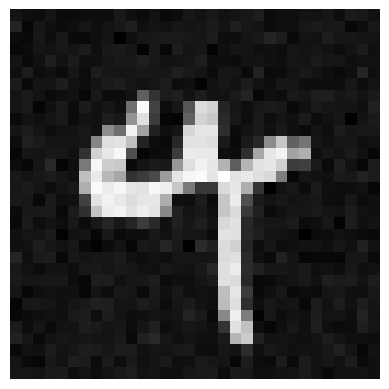

In [93]:
T = 1.
diffusion_model = SimpleBrownianBridgeDiffusion(T, model, 'cuda', trainY, deterministic=False)
samples = diffusion_model.sampling(n_samples=1, use_tqdm=True, n_steps=300)
view_image(samples.cpu()[0])

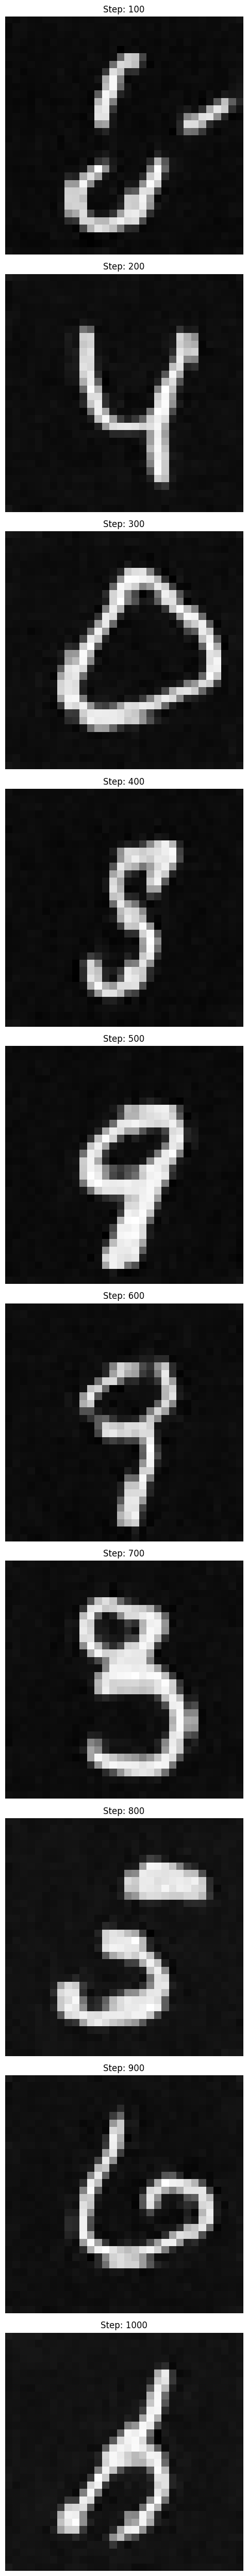

In [87]:
# Generate and visualize samples at different steps
n_samples = 1
n_steps_list = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]
samples = []

for n_steps in n_steps_list:
    sample = diffusion_model.sampling(n_samples=n_samples, use_tqdm=False, n_steps=n_steps)
    samples.append(sample.cpu()[0])

view_images(samples, n_steps_list)

In [94]:
model_denoise = UNet()
checkpoint_path = '/workspace/aim-bridges-models/denoise/checkpoints/batch_64_t_steps_1000_stoch_checkpoint_n_batch_10000.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
model_denoise.load_state_dict(remove_module_prefix(checkpoint))

Loading checkpoint '/workspace/aim-bridges-models/denoise/checkpoints/batch_64_t_steps_1000_stoch_checkpoint_n_batch_10000.pth'


<All keys matched successfully>

100%|██████████| 300/300 [00:04<00:00, 66.17it/s]


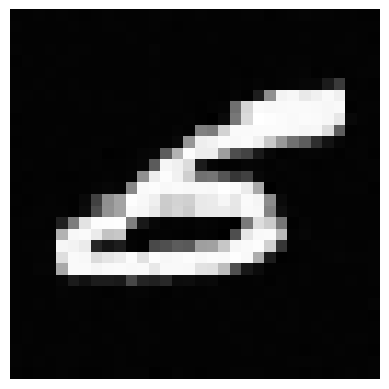

In [95]:
T = 300
diffusion_model_denoise = DiffusionModel(T, model_denoise, 'cuda', trainY)
samples = diffusion_model_denoise.sampling(n_samples=1, use_tqdm=True)
view_image(samples.cpu()[0])

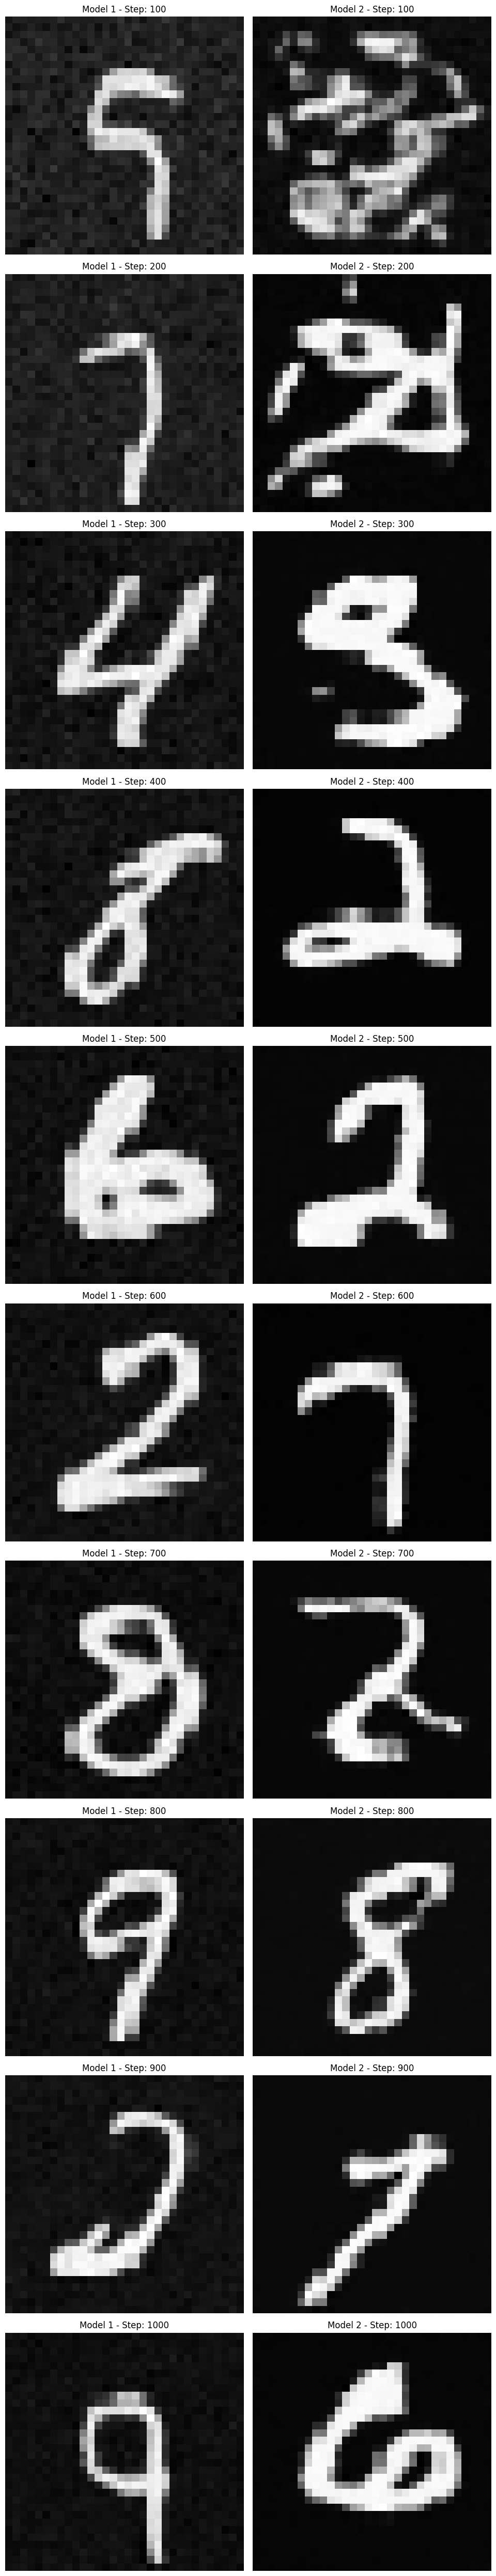

In [96]:
# Generate and visualize samples at different steps for both models
n_samples = 1
n_steps_list = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]

# Samples for the first model
samples_model1 = []
for n_steps in n_steps_list:
    sample = diffusion_model.sampling(n_samples=n_samples, use_tqdm=False, n_steps=n_steps)
    samples_model1.append(sample.cpu()[0])

# Samples for the second model
samples_model2 = []
for n_steps in n_steps_list:
    diffusion_model_denoise = DiffusionModel(n_steps, model_denoise, 'cuda', trainY)
    sample = diffusion_model_denoise.sampling(n_samples=n_samples, use_tqdm=False)
    samples_model2.append(sample.cpu()[0])

# Visualize the samples
view_images_two_models(samples_model1, samples_model2, n_steps_list)